# MERFISH mouse liver

> Uses the **paper-subset** MERSCOPE folder (`MsLiver_Cellbound_paper_subset`), whose
> transform is corrected so transcripts/polygons align onto the mosaic image (the raw
> per-cell QC subset carries a y-offset that must be removed). 

## Step 0 — Configuration

In [1]:
from pathlib import Path
import cellman.spatial as cms

ROOT       = "/bce/groups/pnucolab/analysis/l202255179/UNNAMED"
MERSCOPE   = f"{ROOT}/cellman_paper/data/merfish/MsLiver_Cellbound_paper_subset"

STORE_ROOT = f"{ROOT}/CeLLMan_notebooks/ST_bench/merfish_liver"
ZARR       = f"{STORE_ROOT}/spatialdata.zarr"
CROPS      = f"{STORE_ROOT}/spatialdata_crops"
STORE      = f"{STORE_ROOT}/cellman_spatial"
SCRIPTS    = f"{ROOT}/CeLLMan/cellman/spatial/scripts"

DEVICE     = "cuda:1"      
NCORES     = 30

Path(STORE_ROOT).mkdir(parents=True, exist_ok=True)
print("cellman.spatial", cms.__version__)

/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/scanpy/_utils/__init__.py:33: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  from anndata import __version__ as anndata_version
/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/scanpy/__init__.py:24: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/scanpy/readwrite.py:16: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.i

cellman.spatial 0.1.0


## Step 1 — Load MERSCOPE → SpatialData

In [2]:
import spatialdata as sd
import spatialdata_io

if Path(ZARR).exists():
    sdata = sd.read_zarr(ZARR)
    print("loaded existing", ZARR)
else:
    sdata = spatialdata_io.merscope(MERSCOPE)
    sdata.write(ZARR)
    print("wrote", ZARR)
sdata

INFO     The column "global_x" has now been renamed to "x"; the column "x" was already present in the dataframe,   
         and will be dropped.                                                                                      
INFO     The column "global_y" has now been renamed to "y"; the column "y" was already present in the dataframe,   
         and will be dropped.                                                                                      
WARNING  The `feature_key` column gene is categorical with unknown categories. Please ensure the categories are    
         known before calling `PointsModel.parse()` to avoid significant performance implications due to the need  
         for dask to compute the categories. If you did not use PointsModel.parse() explicitly in your code (e.g.  
         this message is coming from a reader in `spatialdata_io`), please report this finding.                    


/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/functools.py:946: UserWarning: The index of the dataframe is not monotonic increasing. It is recommended to sort the data to adjust the order of the index before calling .parse() (or call `parse(sort=True)`) to avoid possible problems due to unknown divisions.
  return method.__get__(obj, cls)(*args, **kwargs)
/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/legacy_api_wrap/__init__.py:88: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  return fn(*args_all, **kw)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default 

wrote /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/merfish_liver/spatialdata.zarr


SpatialData object, with associated Zarr store: /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/merfish_liver/spatialdata.zarr
├── Images
│     └── 'merfish_MsLiver_Cellbound_paper_subset_z3': DataTree[cyx] (2, 57609, 61313), (2, 28804, 30656), (2, 14402, 15328), (2, 7201, 7664), (2, 3600, 3832)
├── Points
│     └── 'merfish_MsLiver_Cellbound_paper_subset_transcripts': DataFrame with shape: (<Delayed>, 9) (3D points)
├── Shapes
│     └── 'merfish_MsLiver_Cellbound_paper_subset_polygons': GeoDataFrame shape: (34217, 3) (2D shapes)
└── Tables
      └── 'table': AnnData (34217, 307)
with coordinate systems:
    ▸ 'global', with elements:
        merfish_MsLiver_Cellbound_paper_subset_z3 (Images), merfish_MsLiver_Cellbound_paper_subset_transcripts (Points), merfish_MsLiver_Cellbound_paper_subset_polygons (Shapes)

In [4]:
IMAGE_KEY  = "merfish_MsLiver_Cellbound_paper_subset_z3"
POINTS_KEY = "merfish_MsLiver_Cellbound_paper_subset_transcripts"

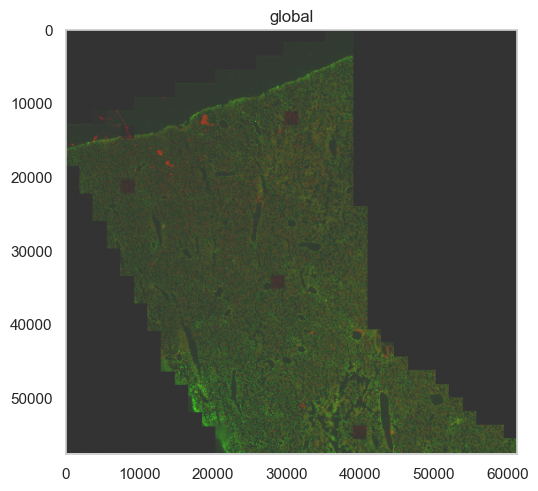

In [4]:
import spatialdata_plot  
sdata.pl.render_images(IMAGE_KEY).pl.show()

## Step 2 — Tile for chunked downsampling

In [5]:
import subprocess, sys
if not Path(CROPS).exists():
    subprocess.run([sys.executable, f"{SCRIPTS}/slice_spatialdata.py",
                    "--sdata-path", ZARR,
                    "--tile-size", "20000",
                    "--output-dir", CROPS,
                    "--image-key", IMAGE_KEY,
                    "--keep-points", POINTS_KEY,
                    "--drop-labels", "--drop-shapes", "--drop-tables"], check=True)
else:
    print("tiles already exist:", CROPS)

SDATA_PATH    : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/merfish_liver/spatialdata.zarr
TILE_SIZE     : 20000.0
OUTPUT_DIR    : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/merfish_liver/spatialdata_crops
MIN_TILE_SIZE : 10000.0
COORD_SYSTEM  : global

SpatialData loaded:
  images : ['merfish_MsLiver_Cellbound_paper_subset_z3']
  labels : []
  points : ['merfish_MsLiver_Cellbound_paper_subset_transcripts']
  shapes : ['merfish_MsLiver_Cellbound_paper_subset_polygons']
  tables : ['table']

Global extent: x=[0.00, 61313.00], y=[0.00, 57609.00]
x_edges: ['0.0', '20000.0', '40000.0', '61313.0']
y_edges: ['0.0', '20000.0', '40000.0', '57609.0']
Grid: 3 rows x 3 cols = 9 tiles

[0,0] x=[0.00,20000.00], y=[0.00,20000.00] -> /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/merfish_liver/spatialdata_crops/r00_c00.zarr


/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


  -> saved (images=['merfish_MsLiver_Cellbound_paper_subset_z3'], labels=[], points=['merfish_MsLiver_Cellbound_paper_subset_transcripts'], shapes=[], tables=[], transcripts=136606, cells=0)
[0,1] x=[20000.00,40000.00], y=[0.00,20000.00] -> /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/merfish_liver/spatialdata_crops/r00_c01.zarr


/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


  -> saved (images=['merfish_MsLiver_Cellbound_paper_subset_z3'], labels=[], points=['merfish_MsLiver_Cellbound_paper_subset_transcripts'], shapes=[], tables=[], transcripts=869753, cells=0)
[0,2] x=[40000.00,61313.00], y=[0.00,20000.00] -> /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/merfish_liver/spatialdata_crops/r00_c02.zarr


/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


... (9 outputs left out)

/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


  -> saved (images=['merfish_MsLiver_Cellbound_paper_subset_z3'], labels=[], points=['merfish_MsLiver_Cellbound_paper_subset_transcripts'], shapes=[], tables=[], transcripts=450960, cells=0)
[2,2] x=[40000.00,61313.00], y=[40000.00,57609.00] -> /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/merfish_liver/spatialdata_crops/r02_c02.zarr


/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


  -> saved (images=['merfish_MsLiver_Cellbound_paper_subset_z3'], labels=[], points=['merfish_MsLiver_Cellbound_paper_subset_transcripts'], shapes=[], tables=[], transcripts=74, cells=0)

Done.
  Total grid cells : 9
  Tiles saved      : 8
  Tiles skipped    : 1
  Output directory : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/merfish_liver/spatialdata_crops

Saved files:
  r00_c00.zarr
  r00_c01.zarr
  r01_c00.zarr
  r01_c01.zarr
  r01_c02.zarr
  r02_c00.zarr
  r02_c01.zarr
  r02_c02.zarr


## Step 3 — `downsample_vector` (transcript path)

Samples voxels from the DAPI/polyT tissue mask and computes the KDE vector field at each.
`revert_image=False`: MERFISH morphology is bright-tissue-on-dark.

In [6]:
ds = cms.SSAMDataset(STORE)
analysis = cms.SSAMAnalysis(ds, ncores=NCORES, verbose=True)

zarr keys: (empty)


In [5]:
adata = analysis.downsample_vector(
    chunked=True, sdata_dir=Path(CROPS),
    n_samples=10, block_um=10, bandwidth=2.5, sampling_distance=1.0,
    image_key=IMAGE_KEY, revert_image=False, gpu_device=DEVICE,
)
adata

downsample_vector (chunked): 8 sdata stores found.
  r00_c00: otsu=43
  r00_c01: otsu=71
  r01_c00: otsu=76
  r01_c01: otsu=87
  r01_c02: otsu=63
  r02_c00: otsu=56
  r02_c01: otsu=80
  r02_c02: otsu=63
  median otsu: 67.0

  [r00_c00]
    kept: 1,908  offset: [250.43764, 1413.861, 0.0]

  [r00_c01]
    kept: 39,795  offset: [2159.967, 614.80457, 0.0]

  [r01_c00]
    kept: 60,761  offset: [211.16199, 2159.9626, 0.0]

  [r01_c01]
    kept: 79,573  offset: [2159.966, 2159.9636, 0.0]

  [r01_c02]
    kept: 976  offset: [4319.938, 3221.3438, 0.0]

  [r02_c00]
    kept: 13,254  offset: [1215.7955, 4319.925, 0.0]

  [r02_c01]
    kept: 34,887  offset: [2159.9702, 4319.9272, 0.0]

  [r02_c02]
    kept: 16  offset: [4319.953, 5728.552, 0.0]
  gene panel union: 307 (per-chunk min=31, max=307)

  total kept (all chunks): 231,170


/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=13, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)


AnnData object with n_obs × n_vars = 231170 × 307
    obs: 'vf_norm'
    obsm: 'spatial'

## Step 4 — `cluster_vectors` (Leiden)

In [6]:
import rapids_singlecell as rsc
rsc.pp.pca(adata, n_comps=50)
rsc.pp.neighbors(adata, n_neighbors=15)
analysis.cluster_vectors(adata, outlier_detection_method=None, resolution=1)
adata

cluster_vectors: backend = rapids_singlecell (GPU)
Found 33 clusters


AnnData object with n_obs × n_vars = 231170 × 307
    obs: 'vf_norm', 'leiden'
    uns: 'pca', 'neighbors', '__cellman_cluster_raw'
    obsm: 'spatial', 'X_pca'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

/tmp/ipykernel_2368954/1295171777.py:2: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata, color="leiden", spot_size=10)


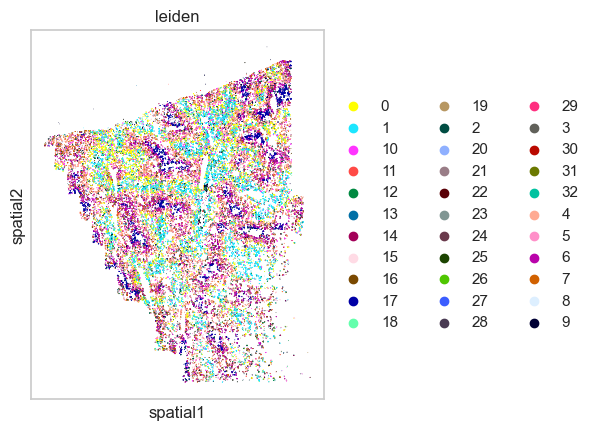

In [7]:
import scanpy as sc
sc.pl.spatial(adata, color="leiden", spot_size=10)

In [8]:
adata.write_h5ad(f"{STORE}/mouse_liver_cls.h5ad")

## Step 5 — Agentic annotation

Run **annotate-mode** on `ssam_clusters.h5ad` (mouse / liver wing) →
`annotation_out/ssam_clusters_annotated.h5ad` with `obs['celltype_annotation']`.

/annotate-mode-v2 Annotate the h5ad below using the mouse-liver-expert agent.

- input : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/merfish_liver/cellman_spatial/mouse_liver_cls.h5ad
- out : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/merfish_liver/cellman_spatial
- tissue : mouse, liver         
- virtual env : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv
- cluster column : leiden
- subcluster-metric : euclidean             
- note : use 5090 GPU on device '1'

In [3]:
import scanpy as sc
anno = sc.read_h5ad(f'{STORE}/annotation_out/mouse_liver_cls_annotated.h5ad')
anno

AnnData object with n_obs × n_vars = 231170 × 307
    obs: 'vf_norm', 'leiden', 'cellman_annotation'
    uns: '__cellman_cluster_raw', 'leiden_colors', 'neighbors', 'pca'
    obsm: 'X_pca', 'spatial'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

/tmp/ipykernel_423530/271924371.py:1: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(anno, color='cellman_annotation', spot_size=10)


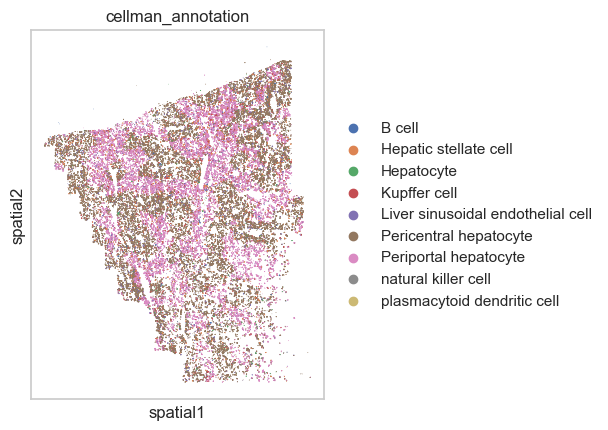

In [4]:
sc.pl.spatial(anno, color='cellman_annotation', spot_size=10)

/tmp/ipykernel_2368954/113200924.py:1: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata, color='cellman_annotation', spot_size=10)


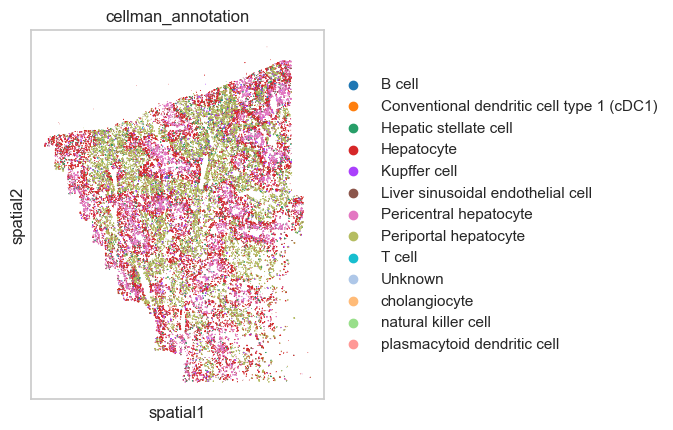

In [10]:
sc.pl.spatial(adata, color='cellman_annotation', spot_size=10)

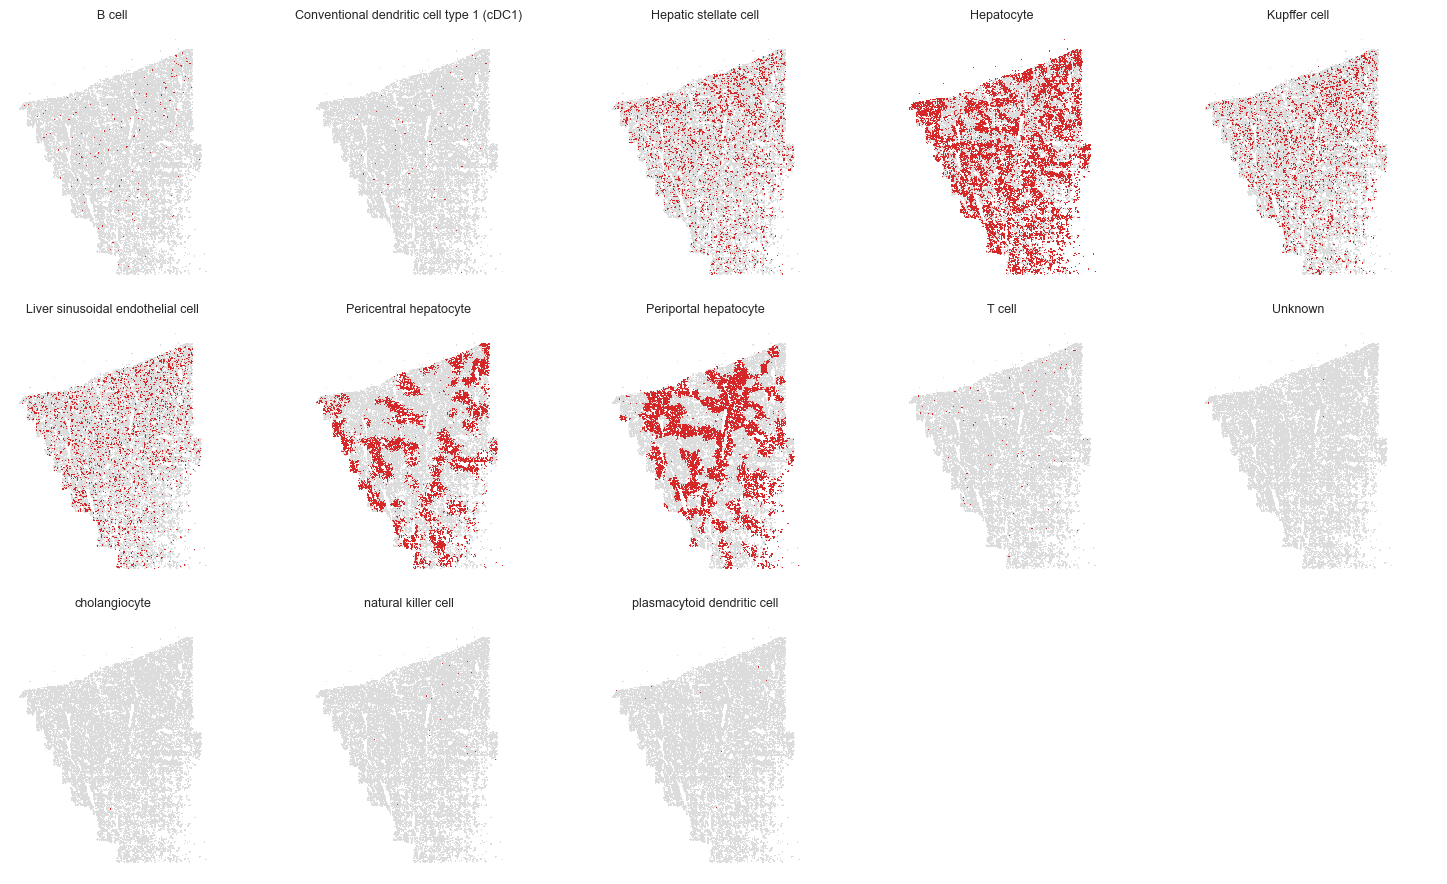

In [11]:
import math, matplotlib.pyplot as plt
COL='cellman_annotation'; PS=0.5; N_COLS=5; BG='#dcdcdc'; FG='#d62728'
xy = adata.obsm['spatial']; labels = adata.obs[COL].astype(str).to_numpy()
cats = list(adata.obs[COL].cat.categories); n=len(cats)
n_cols=min(N_COLS,n); n_rows=math.ceil(n/n_cols)
fig,axes=plt.subplots(n_rows,n_cols,figsize=(3*n_cols,3*n_rows),squeeze=False)
for a_ in axes.flat: a_.set_axis_off()
for i,ct in enumerate(cats):
    a_=axes[i//n_cols,i%n_cols]; m=labels==ct
    a_.scatter(xy[~m,0],xy[~m,1],s=PS,c=BG,linewidths=0,rasterized=True)
    a_.scatter(xy[m,0], xy[m,1], s=PS,c=FG,linewidths=0,rasterized=True)
    a_.set_title(ct,fontsize=9); a_.set_aspect('equal'); a_.invert_yaxis()
fig.tight_layout(); plt.show()

## Step 6 — Merge annotated clusters → centroids

In [ ]:
subprocess.run([sys.executable, f"{SCRIPTS}/merge_clusters.py",
                "--store-dir", STORE,
                "--annotate-out", f"{STORE}/annotation_out",
                "--legacy"], check=True)

## Step 7 — `map_celltypes` (single entry point)

Builds the KDE field chunk-by-chunk and assigns each voxel to its max-correlation centroid.
`map_celltypes` auto-selects GPU/CPU (`force_cpu=True` to force CPU); `method='corr'` is the
transcript default. (Old API: `analysis.map_celltypes_gpu(sdata, ...)`.)

In [ ]:
sdata = sd.read_zarr(ZARR)
analysis.map_celltypes(sdata, method="corr", gpu_device=DEVICE)

## Step 8 — Filter + plot the cell-type map

In [ ]:
analysis.filter_celltypemaps(min_r=0)
ds.extract_spatialdata_scale(sdata)
colors = anno.uns.get("celltype_annotation_colors") if anno is not None else None
# write the map into the SAME sdata: labels + RGB image + annotating table
ds.write_celltype_map(sdata, annotation_csv=f"{STORE}/merged_annotation.csv", colors=colors)
for _el in ("cellman_celltype_map", "cellman_celltype_map_rgb", "cellman_celltype"):
    sdata.write_element(_el, overwrite=True)   # persist outputs into the unified sdata zarr
ds.plot_celltypes_map(save_to_spatialdata=False, show_annotation=True,
                      annotation_csv=f"{STORE}/merged_annotation.csv",
                      colors=colors)